# 10 · Model comparison

[Guide](../README.md) | [Previous](09_Class_Imbalance.ipynb) | [Next](11_Hyperparameter_Optimization.ipynb)

## 1. What problem are we solving?

Which model family best uses the chosen inputs?

## 2. Why does it matter?

Models capture different patterns and have different speed and complexity costs.

## 3. Key concepts

| Term | Simple meaning |
|---|---|
| Linear model | Learn weights for input columns; simple effects are easy to inspect. |
| Tree / forest | A tree learns if/then splits; a forest combines many randomized trees. |
| Boosting | Build models in sequence so later steps improve the combined prediction. |
| RBF SVM | Use a nonlinear similarity rule; scaling and computation cost matter. |
| Fair model comparison | Keep the earlier preprocessing and evaluation folds fixed while changing the learner. |
| Pipeline notation | `clone` copies unfitted settings; `step__setting` changes one pipeline setting. Earlier steps stay fixed during a comparison. |

## 4. Intuitive example

For a kick with player form 70% and keeper saves 30%, `skill_gap=40`. A linear model learns a weight for that gap; a tree can learn a split on it and then check timing; a forest combines many such trees. These are examples of model behavior, not hand-written rules used for predictions.

## 5. Methods to compare

| Model | How it learns | Trade-off |
|---|---|---|
| Logistic regression | Weighted inputs | Simple; limited nonlinear patterns |
| Decision tree | If/then splits | Readable when small; can overfit |
| Random forest | Average randomized trees | Stable; larger and less directly readable |
| Extra Trees | Average trees with more random splits | Fast diversification; may need many trees |
| Gradient boosting | Sequentially improve predictions | Strong nonlinear learner; settings matter |
| RBF SVM | Nonlinear similarity | Needs scaling; can be expensive |
| XGBoost | Regularized boosted trees | Flexible; more tuning choices |
| CatBoost | Boosted trees | Strong candidate; still needs fair validation |

Every learner uses the same earlier preparation and folds. This compares the listed settings, not each family's best possible configuration.

## 6. What we retained from previous notebooks

| Earlier decision | Choice used here |
|---|---|
| Missing | Drop incomplete training rows |
| Scaling | Robust scaling |
| Encoding | One-hot |
| Features | All candidate groups |
| Selection | Drop suspected decoys + L1 |
| Reduction | No PCA |
| Outliers | Add a flag |
| Balancing | Original class counts |

## 7. Setup

**Reusable setup — run this cell, then skip to the lesson.** You do not need to study all these lines now: they load the data and rebuild earlier steps so this notebook works on its own. Revisit the earlier lessons for explanations.

Change `DATA_DIR` for your runtime. The cell starts collapsed where the editor supports it; GitHub may show it expanded. `X` contains inputs; `y` contains known answers. Learned preparation stays inside training folds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)

# Change this one folder on Kaggle or Colab (see the guide).
DATA_DIR = "../data"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("Train:", train.shape, "Test:", test.shape)

# Split train.csv: 80% for training, 20% for a separate validation check.
training_data, validation_data = train_test_split(
    train, test_size=0.20, stratify=train["is_scored"], random_state=2026
)
training_data = training_data.reset_index(drop=True)

# IDs identify rows; they do not describe how a penalty was taken.
id_columns = ["id", "kicker_id", "keeper_id", "match_id"]
X = training_data.drop(columns=id_columns + ["is_scored"])
y = training_data["is_scored"]

from sklearn.base import clone
from sklearn.compose import make_column_selector
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.svm import SVC
from imblearn import FunctionSampler
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

def remove_incomplete_rows(X, y):
    keep = ~X.isna().any(axis=1)
    return X.loc[keep], y[keep]

def drop_suspected_decoys(data):
    return data.drop(columns=["jersey_color", "referee_strictness"], errors="ignore")

def add_relative_features(data):
    data = data.copy()
    data["skill_gap"] = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["foot_advantage"] = data["strong_foot_usage"] - data["weak_foot_usage"]
    data["form_ratio"] = (data["player_last5_scored_percent"] + 1) / (data["goalkeeper_last5_saved_percent"] + 1)
    data["form_interaction"] = data["player_last5_scored_percent"] * data["goalkeeper_last5_saved_percent"] / 100
    data["player_form_squared"] = (data["player_last5_scored_percent"] / 100) ** 2
    data["keeper_form_squared"] = (data["goalkeeper_last5_saved_percent"] / 100) ** 2
    return data

def add_pressure_features(data):
    data = data.copy()
    data["late_close_game"] = ((data["minute_taken"] >= 75) & (data["current_score_diff"].abs() <= 1)).astype(int)
    gap = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["skill_under_pressure"] = gap * data["late_close_game"]
    data["after_90_minutes"] = (data["minute_taken"] > 90).astype(int)
    data["trailing"] = (data["current_score_diff"] < 0).astype(int)
    data["tied_game"] = (data["current_score_diff"] == 0).astype(int)
    data["minute_score_interaction"] = data["minute_taken"] * data["current_score_diff"]
    data["crowd_support"] = (data["home_or_away"] == data["crowd_behind_goal"]).astype(int)
    data["late_final"] = ((data["minute_taken"] >= 75) & (data["match_type"] == "Final")).astype(int)
    return data

def add_environment_features(data):
    data = data.copy()
    data["poor_pitch"] = (data["pitch_condition"] == "Poor").astype(int)
    data["poor_pitch_late"] = data["poor_pitch"] * (data["minute_taken"] >= 75)
    data["humidity_weak_foot"] = data["weather_humidity"] / 100 * data["weak_foot_usage"]
    data["humidity_squared"] = (data["weather_humidity"] / 100) ** 2
    data["temperature_squared"] = data["temperature"] ** 2
    data["log_capacity"] = np.log1p(data["stadium_capacity"])
    return data

def add_features(data):
    data = add_relative_features(data)
    data = add_pressure_features(data)
    return add_environment_features(data)

def suspicious_rows(data):
    # Screening rules, not proof: unusual time, cold weather, or very large venue.
    return ((data["minute_taken"] > 120) |
            (data["temperature"] < 0) |
            (data["stadium_capacity"] > 110000))

def add_outlier_flag(data):
    data = data.copy()
    data["unusual_kick"] = suspicious_rows(data).astype(int)
    return data

numbers = Pipeline([("fill", SimpleImputer(strategy='median')), ("scale", RobustScaler())])
categories = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("numbers", numbers, make_column_selector(dtype_include="number")),
    ("categories", categories, make_column_selector(dtype_exclude="number")),
])

pipeline = Pipeline([
    ("missing_rows", FunctionSampler(func=remove_incomplete_rows, validate=False)),
    ("outlier_values", FunctionTransformer(add_outlier_flag)),
    ("features", FunctionTransformer(add_features)),
    ("decoys", FunctionTransformer(drop_suspected_decoys)),
    ("prepare", preprocess),
    ("selection", SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000, random_state=42))),
    ("model", LogisticRegression(solver="liblinear", max_iter=1000, random_state=42)),
])

# Each fold trains on two parts and predicts the third, unseen part.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def compare(models, X, y):
    rows = []
    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=["f1", "accuracy", "roc_auc"])
        rows.append([name, scores["test_f1"].mean(), scores["test_f1"].std(),
                     scores["test_accuracy"].mean(), scores["test_roc_auc"].mean()])
    columns = ["method", "F1", "F1 spread", "accuracy", "ROC-AUC"]
    return pd.DataFrame(rows, columns=columns).sort_values("F1", ascending=False)

Train: (20000, 20) Test: (6000, 19)


## 8. Experiments

Run the topic-specific steps below. Saved experimental outputs are retained from the earlier runs; regrouping setup does not create a new evaluation.

In [17]:
models = {}
models['Logistic regression'] = clone(pipeline).set_params(model=LogisticRegression(solver="liblinear", max_iter=1000, random_state=42))
models['Decision tree'] = clone(pipeline).set_params(model=DecisionTreeClassifier(max_depth=6, random_state=42))
models['Random forest'] = clone(pipeline).set_params(model=RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=2))
models['Extra trees'] = clone(pipeline).set_params(model=ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=2))
models['Gradient boosting'] = clone(pipeline).set_params(model=HistGradientBoostingClassifier(max_iter=150, random_state=42))
models['RBF support vector machine'] = clone(pipeline).set_params(model=SVC(C=1.0, kernel="rbf", probability=True, random_state=42))
models['XGBoost'] = clone(pipeline).set_params(model=XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, tree_method="hist", eval_metric="logloss", random_state=42, n_jobs=2))
models['CatBoost'] = clone(pipeline).set_params(model=CatBoostClassifier(iterations=200, depth=5, learning_rate=0.05, loss_function="Logloss", random_seed=42, thread_count=2, verbose=False, allow_writing_files=False))

,method,F1,F1 spread,accuracy,ROC-AUC
7,CatBoost,0.944,0.003,0.950,0.991
4,Gradient boosting,0.942,0.002,0.948,0.990
6,XGBoost,0.940,0.003,0.947,0.990
2,Random forest,0.927,0.002,0.935,0.984
3,Extra trees,0.926,0.003,0.934,0.984
0,Logistic regression,0.899,0.002,0.910,0.967
1,Decision tree,0.878,0.005,0.891,0.957
5,RBF support vector machine,0.872,0.002,0.886,0.957


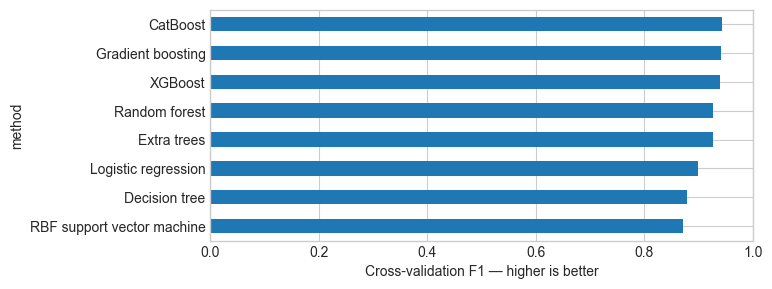

Continue with: CatBoost


In [18]:
results = compare(models, X, y)
display(results.round(4))
results.set_index("method")["F1"].sort_values().plot.barh(figsize=(7, 3))
plt.xlabel("Cross-validation F1 — higher is better")
plt.xlim(0, 1)
plt.show()
print("Continue with:", results.iloc[0]["method"])

**Other alternatives:** KNN uses nearby examples and needs sensible scaling; SVM learns a separating
boundary; naive Bayes assumes feature independence; neural networks learn layers of combinations.
LightGBM is another specialized boosting library. Bigger libraries do not guarantee higher scores.

References: [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html),
[CatBoost classifier](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier).

## 9. Results and decision

| Question | Answer |
|---|---|
| What did we compare? | Logistic regression, decision tree, random forest, Extra Trees, gradient boosting, RBF SVM, XGBoost, and CatBoost. |
| Which performed best? | CatBoost — mean CV F1 0.9440 (rounded saved result). |
| Why did we choose it? | CatBoost has the highest mean F1 among the tested learners using the same prepared inputs and folds. |
| What are its limitations? | This is a limited model/settings comparison, not proof that CatBoost always wins. Different preparation or a larger budget can change the result. |
| What continues to the next notebook? | CatBoost as the selected learner, with the earlier preparation unchanged. |

## 10. Key takeaways and next step

- Compare learners with the same preparation and splits.
- The best tested model is not proof that its whole family always wins.

Next: [11 Hyperparameter Optimization](11_Hyperparameter_Optimization.ipynb).